# Brain Tumor Segmentation and Classification
## Dataset Exploration — Original Figshare Brain Tumor Dataset

**Dataset:** Figshare Brain Tumor Dataset (Cheng et al.)  
**Source:** [Figshare — Brain Tumor Dataset](https://figshare.com/articles/dataset/brain_tumor_dataset/1512427)  
**Description:** 3,064 T1-weighted contrast-enhanced MRI images from 233 patients across three tumor classes: meningioma (708), glioma (1,426), and pituitary tumor (930).  
**Objective:** Explore the original `.mat` file structure, understand all data fields, visualize sample images and annotations, and document the dataset for research paper inclusion.

## 1. Import Required Libraries

We import only the minimal set of libraries needed for loading HDF5-based `.mat` files (v7.3), numerical operations, visualization, and tabular display.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from pathlib import Path
import pandas as pd

# Plot settings
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

## 2. Dataset Directory Structure

The original dataset is split into four subfolders (766 `.mat` files each) plus a cross-validation index file and a README. Below we display the top-level structure.

In [6]:
BASE_DIR = Path(r'../1512427')

items = sorted(BASE_DIR.iterdir(), key=lambda x: (x.is_file(), x.name))
print('Figshare Brain Tumor Dataset/')
for i, item in enumerate(items):
    prefix = '└──' if i == len(items) - 1 else '├──'
    suffix = '/' if item.is_dir() else ''
    print(f'    {prefix} {item.name}{suffix}')

Figshare Brain Tumor Dataset/
    ├── brainTumorDataPublic_1-766/
    ├── brainTumorDataPublic_1533-2298/
    ├── brainTumorDataPublic_2299-3064/
    ├── brainTumorDataPublic_767-1532/
    ├── README 2024.txt
    └── cvind.mat


**Folder descriptions:**
- `brainTumorDataPublic_1-766/` to `brainTumorDataPublic_2299-3064/` — Each contains 766 `.mat` files (one per MRI slice).
- `cvind.mat` — 5-fold cross-validation indices for reproducible train/test splits.
- `README 2024.txt` — Dataset description, data format, acquisition protocol, and citation information.

## 3. Explore Dataset Files

We count the number of subfolders and total `.mat` files across all subfolders, and display sample filenames from each.

In [7]:
data_folders = sorted([f for f in BASE_DIR.iterdir() if f.is_dir()])
print(f'Number of data subfolders: {len(data_folders)}\n')

total_files = 0
for folder in data_folders:
    mat_files = sorted(folder.glob('*.mat'), key=lambda x: int(x.stem))
    count = len(mat_files)
    total_files += count
    sample = [f.name for f in mat_files[:3]]
    print(f'{folder.name}: {count} files — Sample: {sample}')

print(f'\nTotal .mat files: {total_files}')

Number of data subfolders: 4

brainTumorDataPublic_1-766: 766 files — Sample: ['1.mat', '2.mat', '3.mat']
brainTumorDataPublic_1533-2298: 766 files — Sample: ['1533.mat', '1534.mat', '1535.mat']
brainTumorDataPublic_2299-3064: 766 files — Sample: ['2299.mat', '2300.mat', '2301.mat']
brainTumorDataPublic_767-1532: 766 files — Sample: ['767.mat', '768.mat', '769.mat']

Total .mat files: 3064


## 4. Explore `cvind.mat`

The `cvind.mat` file contains pre-defined 5-fold cross-validation indices used by Cheng et al. This ensures reproducibility when comparing results against the original benchmarks.

In [8]:
with h5py.File(BASE_DIR / 'cvind.mat', 'r') as f:
    print('Top-level keys:', list(f.keys()))
    cvind = f['cvind'][()].flatten().astype(int)

print(f'Shape: ({len(cvind)},)')
print(f'Data type: int (stored as float64 in HDF5)')
print(f'Min value: {cvind.min()}, Max value: {cvind.max()}')
print(f'Unique fold IDs: {np.unique(cvind)}')
print(f'\nSamples per fold:')
for fold_id in np.unique(cvind):
    print(f'  Fold {fold_id}: {np.sum(cvind == fold_id)} samples')

Top-level keys: ['cvind']
Shape: (3064,)
Data type: int (stored as float64 in HDF5)
Min value: 1, Max value: 5
Unique fold IDs: [1 2 3 4 5]

Samples per fold:
  Fold 1: 542 samples
  Fold 2: 679 samples
  Fold 3: 572 samples
  Fold 4: 628 samples
  Fold 5: 643 samples


## 5. Explore One `.mat` File — Top-Level Keys

Each `.mat` file (MATLAB v7.3 / HDF5 format) stores a single MRI slice with its associated annotations. We load `1.mat` as a representative sample and inspect its top-level structure.

In [9]:
sample_path = data_folders[0] / '1.mat'

with h5py.File(sample_path, 'r') as f:
    print(f'File: {sample_path.name}')
    print(f'Top-level keys: {list(f.keys())}\n')
    
    for key in f.keys():
        obj = f[key]
        print(f'  {key:15s} — type: {type(obj).__name__}, ', end='')
        if isinstance(obj, h5py.Group):
            print(f'members: {list(obj.keys())}')
        else:
            print(f'shape: {obj.shape}, dtype: {obj.dtype}')

File: 1.mat
Top-level keys: ['cjdata']

  cjdata          — type: Group, members: ['PID', 'image', 'label', 'tumorBorder', 'tumorMask']


## 6. Explore the `cjdata` Structure

The `cjdata` group holds all per-image fields. We enumerate its field names, data types, and shapes.

In [10]:
with h5py.File(sample_path, 'r') as f:
    cjdata = f['cjdata']
    print(f'Type: HDF5 Group')
    print(f'Field names: {list(cjdata.keys())}\n')
    
    print('--- Field Overview ---')
    for field in sorted(cjdata.keys()):
        ds = cjdata[field]
        print(f'  {field:15s}  shape={str(ds.shape):15s}  dtype={ds.dtype}')

Type: HDF5 Group
Field names: ['PID', 'image', 'label', 'tumorBorder', 'tumorMask']

--- Field Overview ---
  PID              shape=(6, 1)           dtype=uint16
  image            shape=(512, 512)       dtype=int16
  label            shape=(1, 1)           dtype=float64
  tumorBorder      shape=(1, 38)          dtype=float64
  tumorMask        shape=(512, 512)       dtype=uint8


**Field descriptions:**

| Field | Description |
|---|---|
| `label` | Tumor class: 1 = meningioma, 2 = glioma, 3 = pituitary tumor |
| `PID` | Patient ID stored as uint16 character codes (decode to string) |
| `image` | 2D MRI image (grayscale, 512×512, int16) |
| `tumorBorder` | Flattened coordinates of manually delineated tumor boundary [x₁, y₁, x₂, y₂, ...] |
| `tumorMask` | Binary mask (512×512, uint8) where 1 = tumor region |

## 7. Detailed Field Exploration

We examine each field individually — data type, shape, sample value, and a brief explanation.

In [11]:
# Load all fields from the sample file
with h5py.File(sample_path, 'r') as f:
    cd = f['cjdata']
    image = cd['image'][()]
    mask  = cd['tumorMask'][()]
    border = cd['tumorBorder'][()]
    label_val = int(cd['label'][()].flatten()[0])
    pid_raw = cd['PID'][()]

label_map = {1: 'Meningioma', 2: 'Glioma', 3: 'Pituitary Tumor'}

### 7.1 `label`

In [12]:
print(f'Data type : float64 (stored), represents integer class')
print(f'Shape     : (1, 1)')
print(f'Value     : {label_val}')
print(f'Meaning   : {label_map[label_val]}')
print(f'Encoding  : 1 = Meningioma, 2 = Glioma, 3 = Pituitary Tumor')

Data type : float64 (stored), represents integer class
Shape     : (1, 1)
Value     : 1
Meaning   : Meningioma
Encoding  : 1 = Meningioma, 2 = Glioma, 3 = Pituitary Tumor


### 7.2 `PID`

In [13]:
pid_str = ''.join([chr(c) for c in pid_raw.flatten()])
print(f'Data type : uint16 (character codes)')
print(f'Shape     : {pid_raw.shape}')
print(f'Raw value : {pid_raw.flatten()}')
print(f'Decoded   : "{pid_str}"')
print('Meaning   : Unique patient identifier (multiple slices may share the same PID)')

Data type : uint16 (character codes)
Shape     : (6, 1)
Raw value : [49 48 48 51 54 48]
Decoded   : "100360"
Meaning   : Unique patient identifier (multiple slices may share the same PID)


### 7.3 `image`

In [14]:
print(f'Data type : {image.dtype}')
print(f'Shape     : {image.shape}')
print(f'Min value : {image.min()}')
print(f'Max value : {image.max()}')
print(f'Mean      : {image.mean():.2f}')
print('Meaning   : T1-weighted contrast-enhanced MRI slice (grayscale, 512×512)')

Data type : int16
Shape     : (512, 512)
Min value : 0
Max value : 3366
Mean      : 441.48
Meaning   : T1-weighted contrast-enhanced MRI slice (grayscale, 512×512)


### 7.4 `tumorMask`

In [15]:
print(f'Data type     : {mask.dtype}')
print(f'Shape         : {mask.shape}')
print(f'Unique values : {np.unique(mask)}')
print(f'Tumor pixels  : {np.sum(mask == 1)}')
print(f'Tumor area %  : {100 * np.sum(mask == 1) / mask.size:.2f}%')
print('Meaning       : Binary segmentation mask (1 = tumor, 0 = background)')

Data type     : uint8
Shape         : (512, 512)
Unique values : [0 1]
Tumor pixels  : 4569
Tumor area %  : 1.74%
Meaning       : Binary segmentation mask (1 = tumor, 0 = background)


### 7.5 `tumorBorder`

In [16]:
border_flat = border.flatten()
print(f'Data type       : {border.dtype}')
print(f'Shape           : {border.shape}')
print(f'Total values    : {border.size}')
print(f'Number of points: {border.size // 2}')
print(f'First 10 values : {border_flat[:10]}')
print('Meaning         : Flattened [x1, y1, x2, y2, ...] coordinates of the manually delineated tumor boundary')

Data type       : float64
Shape           : (1, 38)
Total values    : 38
Number of points: 19
First 10 values : [267.61524501 231.37568058 277.83666062 248.10163339 289.91651543
 250.8892922  305.71324864 253.676951   318.72232305 249.9600726 ]
Meaning         : Flattened [x1, y1, x2, y2, ...] coordinates of the manually delineated tumor boundary


## 8. Visualize Sample Data

We visualize the MRI image alongside its tumor mask, boundary overlay, and tumor center for the sample file.

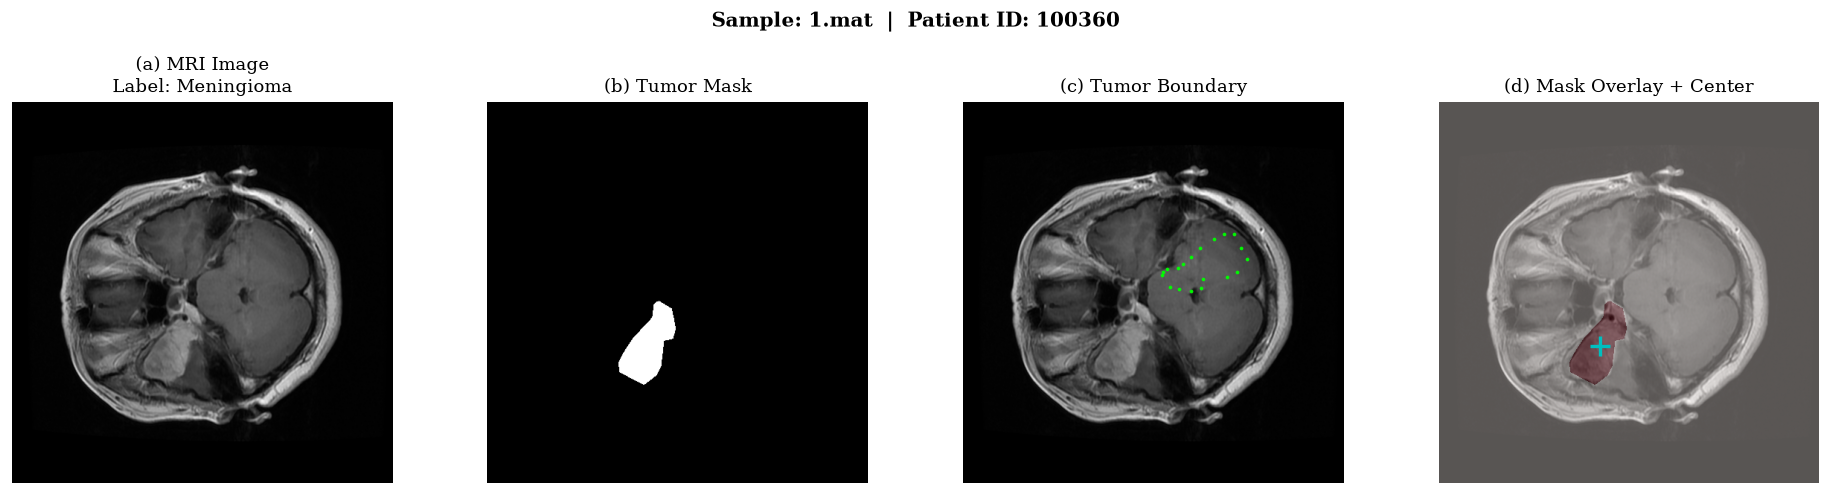

In [17]:
# Extract border coordinates
border_x = border_flat[0::2]
border_y = border_flat[1::2]

# Compute tumor center from mask
ys, xs = np.where(mask == 1)
center_x, center_y = xs.mean(), ys.mean()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# (a) MRI Image
axes[0].imshow(image, cmap='gray')
axes[0].set_title(f'(a) MRI Image\nLabel: {label_map[label_val]}')
axes[0].axis('off')

# (b) Tumor Mask
axes[1].imshow(mask, cmap='gray')
axes[1].set_title('(b) Tumor Mask')
axes[1].axis('off')

# (c) Image + Boundary Overlay
axes[2].imshow(image, cmap='gray')
axes[2].scatter(border_x, border_y, c='lime', s=1.5, alpha=0.9)
axes[2].set_title('(c) Tumor Boundary')
axes[2].axis('off')

# (d) Image + Mask Overlay + Center
axes[3].imshow(image, cmap='gray')
axes[3].imshow(mask, cmap='Reds', alpha=0.35)
axes[3].plot(center_x, center_y, 'c+', markersize=12, markeredgewidth=2)
axes[3].set_title('(d) Mask Overlay + Center')
axes[3].axis('off')

pid_str_title = ''.join([chr(c) for c in pid_raw.flatten()])
plt.suptitle(f'Sample: {sample_path.name}  |  Patient ID: {pid_str_title}', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 9. Visualize One Sample per Tumor Class

To illustrate inter-class variability, we display one representative MRI slice with its tumor mask overlay for each of the three tumor classes.

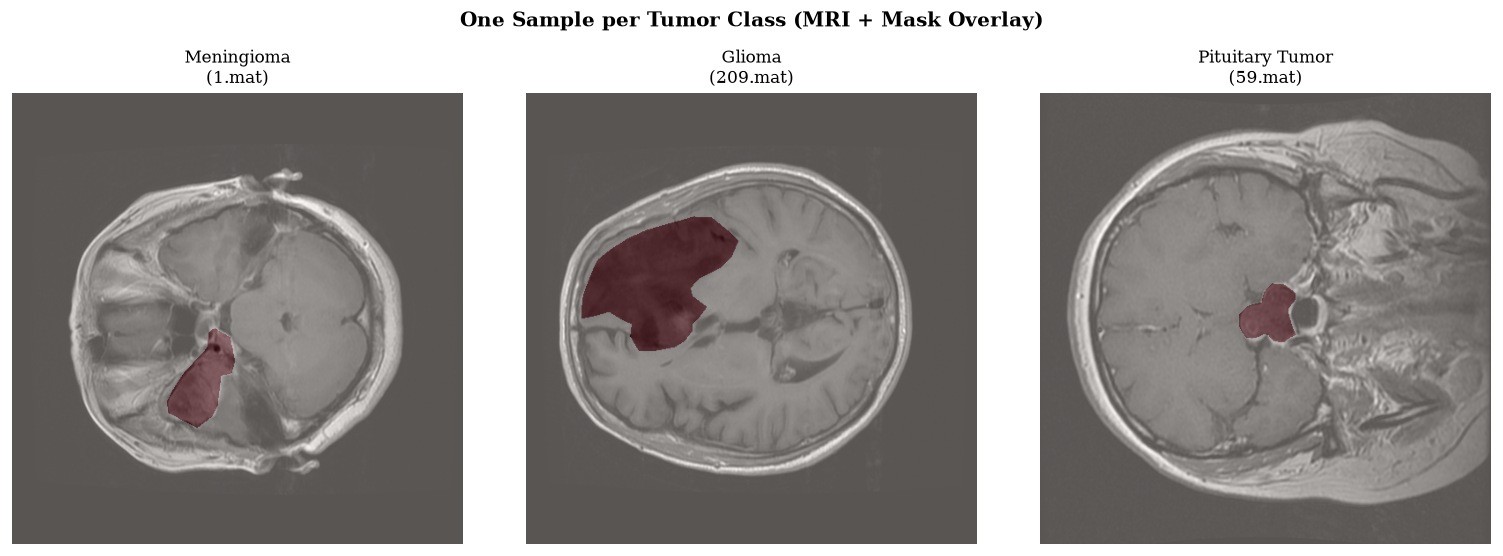

In [18]:
# Collect all .mat file paths
all_mat_files = []
for folder in data_folders:
    all_mat_files.extend(sorted(folder.glob('*.mat'), key=lambda x: int(x.stem)))

# Find one sample per class
class_samples = {}
for fpath in all_mat_files:
    if len(class_samples) == 3:
        break
    with h5py.File(fpath, 'r') as f:
        lbl = int(f['cjdata']['label'][()].flatten()[0])
        if lbl not in class_samples:
            class_samples[lbl] = {
                'name': fpath.name,
                'image': f['cjdata']['image'][()],
                'mask': f['cjdata']['tumorMask'][()]
            }

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for i, lbl in enumerate(sorted(class_samples)):
    s = class_samples[lbl]
    axes[i].imshow(s['image'], cmap='gray')
    axes[i].imshow(s['mask'], cmap='Reds', alpha=0.35)
    axes[i].set_title(f'{label_map[lbl]}\n({s["name"]})', fontsize=10)
    axes[i].axis('off')

plt.suptitle('One Sample per Tumor Class (MRI + Mask Overlay)', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 10. Class Distribution

We scan all 3,064 `.mat` files to count the number of slices per tumor class and visualize the distribution.

In [19]:
labels_all = []
for fpath in all_mat_files:
    with h5py.File(fpath, 'r') as f:
        labels_all.append(int(f['cjdata']['label'][()].flatten()[0]))

labels_arr = np.array(labels_all)

print('Class Distribution:')
for lbl in [1, 2, 3]:
    count = np.sum(labels_arr == lbl)
    print(f'  {label_map[lbl]:20s}: {count:4d} slices ({100*count/len(labels_arr):.1f}%)')
print(f'  {"Total":20s}: {len(labels_arr)}')

Class Distribution:
  Meningioma          :  708 slices (23.1%)
  Glioma              : 1426 slices (46.5%)
  Pituitary Tumor     :  930 slices (30.4%)
  Total               : 3064


## 11. Research Paper Summary

> The following paragraph can be directly included in the *Dataset* section of a research paper.

---

The dataset used in this study is the publicly available **Figshare Brain Tumor Dataset** curated by Cheng et al. It comprises **3,064 T1-weighted contrast-enhanced (T1-CE) MRI slices** acquired from **233 patients** at Nanfang Hospital, Guangzhou, and General Hospital, Tianjin Medical University, China. The images are categorized into three tumor classes: **meningioma (708 slices)**, **glioma (1,426 slices)**, and **pituitary tumor (930 slices)**. Each sample is stored as a MATLAB v7.3 (HDF5) `.mat` file containing a structured group (`cjdata`) with five fields: the grayscale MRI image (`image`, 512×512, int16), a binary tumor segmentation mask (`tumorMask`, 512×512, uint8), manually delineated tumor boundary coordinates (`tumorBorder`, float64), a class label (`label`, integer: 1–3), and a patient identifier (`PID`, encoded as uint16 character codes). The dataset also includes pre-defined 5-fold cross-validation indices (`cvind.mat`) to facilitate reproducible benchmarking. All images have an in-plane resolution of 512×512 pixels (0.49×0.49 mm²), a slice thickness of 6 mm, and a slice gap of 1 mm.

---

---
**End of Notebook** — `01_Dataset_Exploration.ipynb`